# Rope and photons, advanced: how many photons a Sentinel-2 pixel and a drone pixel collect

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Rope and photons](https://openskylab.space/edu_viz_rope_and_photons.html) · [česká verze](rope_and_photons_pro_cs.ipynb)

The advanced version of the photons notebook. From a real Sentinel-2 scene over Roztoky you compute how many photons reach the detector in bands B02, B04, B08 and B11 during the time the satellite crosses one pixel, what signal-to-noise ratio follows from that and how the telescope size changes it. You then do the same calculation for a drone camera and find out why a small lens low above the ground collects about as many photons as a telescope in orbit.

**Goal:** compute radiance and the number of photoelectrons per pixel from L1C reflectance, derive the signal-to-noise ratio √N, simulate photon noise for different pupils, compare the satellite with a drone through the product A·Ω, and check how SNR grows when pixels are merged and how it relates to quantisation.

**Data:** Copernicus Sentinel-2B L1C `S2B_MSIL1C_20240721T100559_N0510_R022_T33UVR_20240721T121133` (21 July 2024) from the Google Cloud public archive: the MTD_MSIL1C and MTD_TL metadata and 4 × 4 km windows of bands B02, B04, B08 and B11 around Roztoky, about 2 MB. The instrument parameters (150 mm pupil, 786 km orbit altitude) are taken from the MSI description. The efficiency ETA and the drone parameters are indicative estimates: the real instrument is more complex (detector types, several lines summed in some bands), so the numbers show the order of magnitude, not the exact SNR of Sentinel-2.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 60 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and the Sentinel-2 scene

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re, requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pyproj import Transformer
from scipy.constants import h, c
warnings.filterwarnings("ignore")

From the top-of-atmosphere reflectance ρ we get radiance L = ρ · E0 · U · cos(θs) / π, where E0 is the solar irradiance in the band, U the Earth–Sun distance correction and θs the solar zenith angle. All three values are in the scene metadata.

In [3]:
BASE = ("https://storage.googleapis.com/gcp-public-data-sentinel-2/tiles/33/U/VR/"
        "S2B_MSIL1C_20240721T100559_N0510_R022_T33UVR_20240721T121133.SAFE/")
LON, LAT, HALF = 14.375, 50.145, 2000             # ◀ parameter: window centre (near Roztoky) and half width (m)
mtd = requests.get(BASE + "MTD_MSIL1C.xml", timeout=60).text
man = requests.get(BASE + "manifest.safe", timeout=60).text
tile_md = requests.get(BASE + re.search(r'href="\./(GRANULE/[^"]+/MTD_TL\.xml)"', man).group(1), timeout=60).text
U = float(re.search(r"<U>([\d.]+)</U>", mtd).group(1))                   # Earth–Sun distance correction on the image date
Q = float(re.search(r"<QUANTIFICATION_VALUE[^>]*>([\d.]+)", mtd).group(1))
OFFSET = {int(b): float(v) for b, v in re.findall(r'<RADIO_ADD_OFFSET band_id="(\d+)">(-?[\d.]+)', mtd)}
SZA = float(re.search(r"<Mean_Sun_Angle>\s*<ZENITH_ANGLE[^>]*>([\d.]+)", tile_md).group(1))
BANDS = {"B02": (1, 10), "B04": (3, 10), "B08": (7, 10), "B11": (11, 20)}  # name: (index in the metadata, pixel size in m)
info = {}
for m in re.finditer(r'<Spectral_Information bandId="(\d+)" physicalBand="(\w+)">(.*?)</Spectral_Information>', mtd, re.S):
    bid, name, body = int(m.group(1)), m.group(2), m.group(3)
    vals = np.array(re.search(r"<VALUES>(.*?)</VALUES>", body).group(1).split(), float)
    info[bid] = {"lambda_um": float(re.search(r'<CENTRAL unit="nm">([\d.]+)', body).group(1)) / 1000,
                 "width_um": vals.sum() / vals.max() / 1000,                  # equivalent band width (SRF step 1 nm)
                 "E0": float(re.search(rf'<SOLAR_IRRADIANCE bandId="{bid}"[^>]*>([\d.]+)', mtd).group(1))}
x, y = Transformer.from_crs(4326, 32633, always_xy=True).transform(LON, LAT)
rad = {}
for name, (bid, gsd) in BANDS.items():
    href = re.search(rf'href="\./(GRANULE/[^"]+IMG_DATA/[^"]+_{name}\.jp2)"', man).group(1)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2), rasterio.open("/vsicurl/" + BASE + href) as r:
        w = rasterio.windows.from_bounds(x - HALF, y - HALF, x + HALF, y + HALF, r.transform).round_offsets().round_lengths()
        dn = r.read(1, window=w).astype(float)
    rho = (dn + OFFSET[bid]) / Q                                               # TOA reflectance
    rad[name] = rho * info[bid]["E0"] * U * np.cos(np.radians(SZA)) / np.pi    # radiance W·m⁻²·sr⁻¹·µm⁻¹
    print(f"{name}: {dn.shape[0]} × {dn.shape[1]} pixels, median radiance {np.median(rad[name]):.1f} W·m⁻²·sr⁻¹·µm⁻¹")
print(f"solar zenith angle {SZA:.1f}°, U = {U:.4f}")

B02: 400 × 400 pixels, median radiance 54.8 W·m⁻²·sr⁻¹·µm⁻¹


B04: 400 × 400 pixels, median radiance 32.9 W·m⁻²·sr⁻¹·µm⁻¹


B08: 400 × 400 pixels, median radiance 67.3 W·m⁻²·sr⁻¹·µm⁻¹


B11: 200 × 200 pixels, median radiance 12.4 W·m⁻²·sr⁻¹·µm⁻¹
solar zenith angle 31.5°, U = 0.9681


## 2. The photon budget of a pixel

A telescope with pupil area A sees one pixel under the solid angle Ω = (pixel / height)². The energy arriving from the pixel in time t is L · A · Ω · Δλ · t; divided by the photon energy h·c/λ and multiplied by the efficiency ETA it gives the number of photoelectrons N. For t we take the time the satellite ground track needs to cross one pixel. Photons arrive at random (Poisson), so the noise is √N and the signal-to-noise ratio SNR = √N. Detector and electronics noise are neglected here.

In [4]:
D_PUPIL = 0.150        # ◀ parameter: telescope entrance pupil diameter (m); MSI has an equivalent of 150 mm
H_ORBIT = 786e3        # ◀ parameter: orbit altitude (m)
ETA = 0.3              # ◀ parameter: fraction of photons turned into electrons (optics transmission × quantum efficiency), an estimate
GM, R_E = 3.986004418e14, 6371e3
v_ground = np.sqrt(GM / (R_E + H_ORBIT)) * R_E / (R_E + H_ORBIT)              # ground-track speed of the satellite
A = np.pi * (D_PUPIL / 2) ** 2

def photons(L, lam_um, width_um, gsd, A=A, H=H_ORBIT, t=None, eta=ETA):
    """Number of photoelectrons in one pixel during the time the satellite takes to cross one pixel."""
    t = gsd / v_ground if t is None else t
    omega = (gsd / H) ** 2                                                    # solid angle of the pixel
    energy = L * A * omega * width_um * t                                     # J
    return eta * energy / (h * c / (lam_um * 1e-6))

rows = {}
for name, (bid, gsd) in BANDS.items():
    i = info[bid]
    N = photons(rad[name], i["lambda_um"], i["width_um"], gsd)
    rad[name + "_N"] = N
    rows[name] = {"λ (µm)": i["lambda_um"], "width (µm)": i["width_um"], "pixel (m)": gsd, "pixel crossing time (ms)": gsd / v_ground * 1000,
                  "N dark (2 %)": np.percentile(N, 2), "N median": np.median(N), "N bright (98 %)": np.percentile(N, 98),
                  "SNR √N median": np.sqrt(np.median(N))}
print(f"ground-track speed {v_ground / 1000:.2f} km/s, pupil area {A * 1e4:.0f} cm²")
pd.DataFrame(rows).T.round(3)

ground-track speed 6.64 km/s, pupil area 177 cm²


,λ (µm),width (µm),pixel (m),pixel crossing time (ms),N dark (2 %),N median,N bright (98 %),SNR √N median
B02,0.492,0.061,10.0,1.505,8842.999,10609.602,15130.909,103.003
B04,0.665,0.029,10.0,1.505,2257.681,4090.503,10453.507,63.957
B08,0.833,0.084,10.0,1.505,6239.238,30672.094,46519.759,175.135
B11,1.610,0.091,20.0,3.011,12571.231,94763.762,184011.647,307.837


> **✏️ Task 1.** Why does B11 have the most photoelectrons although the radiance in the shortwave infrared is lower than in the near infrared? Split the difference between B04 and B11 into the contributions of band width, wavelength (photon energy), pixel size and crossing time.

*Your answer:* 

> **✏️ Task 2.** Compare the SNR of dark (2 %) and bright (98 %) pixels in B04. Which surfaces in the window are they? Change `ETA` to 0.6 and then to 0.15: how does SNR change, and why only with the square root?

*Your answer:* 

## 3. What photon noise looks like

We simulate the B04 image as pupils of different size would record it: instead of the expected count N we draw a random number from the Poisson distribution for each pixel. The terrain is the same in all three images, only the noise changes.

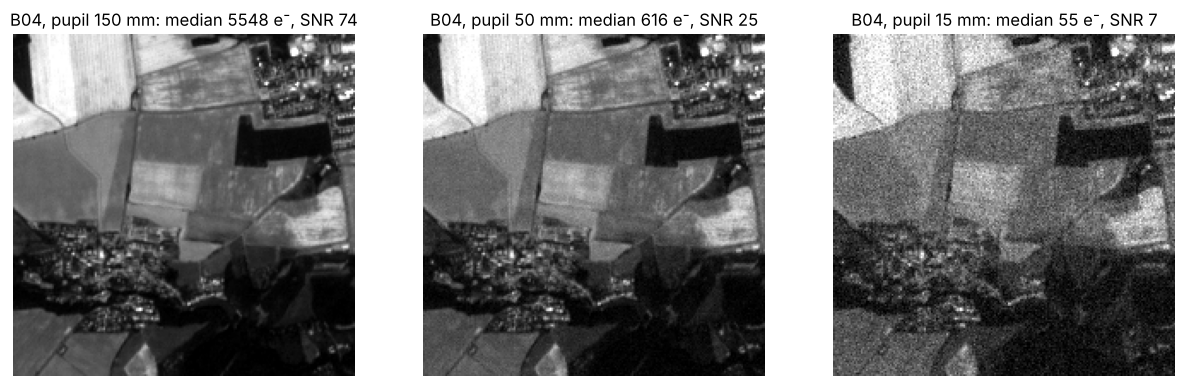

In [5]:
DIAMETERS = [0.150, 0.050, 0.015]    # ◀ parameter: pupil diameters to compare (m)
rng = np.random.default_rng(1)
L4 = rad["B04"][:200, :200]
bid, gsd = BANDS["B04"]
fig, ax = plt.subplots(1, len(DIAMETERS), figsize=(5 * len(DIAMETERS), 5))
for a, D in zip(ax, DIAMETERS):
    N = photons(L4, info[bid]["lambda_um"], info[bid]["width_um"], gsd, A=np.pi * (D / 2) ** 2)
    img = rng.poisson(N)                                                      # photons arrive at random (Poisson distribution)
    a.imshow(img, cmap="gray", vmin=np.percentile(img, 1), vmax=np.percentile(img, 99))
    a.set_title(f"B04, pupil {D * 1000:.0f} mm: median {np.median(N):.0f} e⁻, SNR {np.sqrt(np.median(N)):.0f}"); a.axis("off")
plt.show()

> **✏️ Task 3.** The pupil shrinks three times (150 → 50 mm). By what factor does N drop, and by what factor SNR? At what pupil diameter would the median SNR in B04 fall below 10? Check by changing `DIAMETERS`.

*Your answer:* 

## 4. Drone against satellite

For the drone we use the same band B04 and the same radiance, because the scene is the same. The exposure is the longest one that keeps the image from blurring by more than one pixel during flight (pixel / speed). The drone parameters are indicative and correspond to a small multispectral camera.

In [6]:
DRONE = dict(D=0.003, H=100.0, gsd=0.05, speed=8.0)   # ◀ parameter: drone: pupil (m), flight height (m), ground pixel (m), speed (m/s), indicative
bid, gsd = BANDS["B04"]
Lmed = float(np.median(rad["B04"]))
cmp = {}
for label, D, H, g, t in [("Sentinel-2 MSI", D_PUPIL, H_ORBIT, gsd, gsd / v_ground),
                          ("drone", DRONE["D"], DRONE["H"], DRONE["gsd"], DRONE["gsd"] / DRONE["speed"])]:
    Ap, om = np.pi * (D / 2) ** 2, (g / H) ** 2
    N = photons(Lmed, info[bid]["lambda_um"], info[bid]["width_um"], g, A=Ap, H=H, t=t)
    cmp[label] = {"pupil area (cm²)": Ap * 1e4, "pixel solid angle (sr)": om, "A·Ω (m²·sr)": Ap * om, "exposure (ms)": t * 1000, "N (e⁻)": N, "SNR √N": np.sqrt(N)}
pd.DataFrame(cmp).T.style.format("{:.3g}")

,pupil area (cm²),pixel solid angle (sr),A·Ω (m²·sr),exposure (ms),N (e⁻),SNR √N
Sentinel-2 MSI,177,1.62e-10,2.86e-12,1.51,4.09e+03,64
drone,0.0707,2.5e-07,1.77e-12,6.25,1.05e+04,102


> **✏️ Task 4.** The drone pupil has about 2500 times smaller area than the MSI pupil, and yet the number of photoelectrons is comparable, even higher. Explain it with the product A·Ω and the exposure time. What happens to N when the drone flies twice as high with the same camera (the pixel doubles)?

*Your answer:* 

## 5. Merging pixels and quantisation

Merging n × n pixels adds up the photoelectrons: the signal grows with n², the noise with n, so SNR grows with n. At the end we compare photon noise with the quantisation step: the L1C value is an integer (DN) and one DN step corresponds to a certain number of electrons.

In [7]:
bid, _ = BANDS["B04"]
N10 = np.median(rad["B04_N"])
rows = []
for n in [1, 2, 3, 6]:                    # merging n × n pixels of 10 m (n = 2 corresponds to a 20 m pixel)
    rows.append({"pixel (m)": 10 * n, "N (e⁻)": N10 * n * n, "SNR": np.sqrt(N10 * n * n)})
print(pd.DataFrame(rows).round(0).to_string(index=False))
# quantisation: the step of one DN in electrons
step_rho = 1 / Q
step_L = step_rho * info[bid]["E0"] * U * np.cos(np.radians(SZA)) / np.pi
step_e = photons(step_L, info[bid]["lambda_um"], info[bid]["width_um"], 10)
print(f"one DN in B04 = {step_e:.1f} e⁻ (at ETA = {ETA}); quantisation noise = step/√12 = {step_e / np.sqrt(12):.1f} e⁻, photon noise at the median = {np.sqrt(N10):.0f} e⁻")

 pixel (m)   N (e⁻)   SNR
        10   4091.0  64.0
        20  16362.0 128.0
        30  36815.0 192.0
        60 147258.0 384.0
one DN in B04 = 4.9 e⁻ (at ETA = 0.3); quantisation noise = step/√12 = 1.4 e⁻, photon noise at the median = 64 e⁻


> **✏️ Task 5.** By what factor does SNR grow when 10 m pixels are merged into 60 m? What do you lose? Does L1C quantisation matter for the accuracy of the values, or does photon noise dominate? What would happen if reflectance were stored with only 8 bits (step 1/255)?

*Your answer:* 

> **✏️ Extension (optional).** Change `H_ORBIT` to 500 km and `D_PUPIL` so that SNR stays the same. Compare the result with smaller Earth observation satellites you know something about.

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA; L1C from the Google Cloud public archive (`gcp-public-data-sentinel-2`). Licence: [Legal notice on the use of Copernicus Sentinel Data](https://sentinels.copernicus.eu/documents/247904/690755/Sentinel_Data_Legal_Notice), free use with attribution.
- ESA: *Sentinel-2 MSI Instrument*, technical guide (https://sentinel.esa.int/web/sentinel/technical-guides/sentinel-2-msi/msi-instrument).
- The multispectral instrument of the Sentinel2 program. *Proc. SPIE* 10566, 105660H (ICSO 2008). https://doi.org/10.1117/12.2308278
- Constants h and c: exactly defined SI values since 2019, taken from `scipy.constants`.

### How to cite

OpenSkyLab (2026). Rope and photons, advanced: how many photons a Sentinel-2 pixel and a drone pixel collect [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/rope_and_photons_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*